In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import keras
import tensorflow as tf

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
count = 0
for dirname, _, filenames in os.walk('/kaggle/input'):
    count +=1
#     print(dirname)
#     for filename in filenames:
#         print(os.path.join(dirname, filename))
#         continue
print('Count:', count)

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
print(tf.__version__)
print(keras.__version__)
import sys
print("Python version:", sys.version)

2.15.0
3.0.5
Python version: 3.10.13 | packaged by conda-forge | (main, Dec 23 2023, 15:36:39) [GCC 12.3.0]


## Global Perameteres

In [3]:
FAST_RUN = False
IMAGE_WIDTH=224
IMAGE_HEIGHT=224
IMAGE_SIZE=(IMAGE_WIDTH, IMAGE_HEIGHT)
IMAGE_CHANNELS=3
# batch_size = 128

## Loading the Images

Here we are defining a function, Read_Images, with the purpose of loading in the data from 70-dog-breeds-image-data-set. The function defines an empty list to store tuples of the filename, and the folder name that file was found showing the breed of the dog in the image. This is then put into a dataframe and returned. We will use this function to create our train, test, and validation data frames.

In [4]:
import os
import pandas as pd

# Define the directory path
base_dir = '../input/70-dog-breedsimage-data-set/'

# Define the directory names for test, train, and validation sets
test_dir = os.path.join(base_dir, 'test/')
train_dir = os.path.join(base_dir, 'train/')
val_dir = os.path.join(base_dir, 'valid/')

def Read_Images(image_path):
    # Initialize an empty list to store tuples of (filename, breed_type)
    file_info = []

    # Iterate through each directory (breed type) in the base directory
    for breed_type in os.listdir(image_path):
        # Construct the full path of the breed directory
        breed_dir = os.path.join(image_path, breed_type)

        # Check if the directory exists and is indeed a directory
        if os.path.isdir(breed_dir):
            # Iterate through each file in the breed directory
            for filename in os.listdir(breed_dir):
#                 print('filename:', filename)
#                 print('breedDir:', breed_dir)
                # Append only breed and filename, separated by a slash
                file_info.append((f"{breed_type}/{filename}", breed_type))  # Modified line

    # Create a DataFrame from the list of tuples
    df = pd.DataFrame(file_info, columns=['filename', 'breed'])

    # Display the DataFrame
    # print(df)
    return df

train_df = Read_Images(train_dir)
test_df = Read_Images(test_dir)
val_df = Read_Images(val_dir)

train_df

,filename,breed
0,Cocker/029.jpg,Cocker
1,Cocker/014.jpg,Cocker
2,Cocker/109.jpg,Cocker
3,Cocker/034.jpg,Cocker
4,Cocker/024.jpg,Cocker
...,...,...
7941,Corgi/053.jpg,Corgi
7942,Corgi/013.jpg,Corgi
7943,Corgi/016.jpg,Corgi
7944,Corgi/044.jpg,Corgi


### Label encoding the breed label

We will then convert the breed names in the DataFrame column 'breed' into numerical labels using a LabelEncoder. This assigns a unique number to each breed. It then creates one-hot encoded vectors from those numerical labels. One-hot encoding represents each breed with a binary vector where a single value of 1 indicates the specific breed. The code adds a new column 'breed_encoded_one_hot' to the DataFrame, containing those one-hot encoded vectors.

In [5]:
# from sklearn.preprocessing import LabelEncoder
# from tensorflow.keras.utils import to_categorical

# # Use LabelEncoder to convert breed strings to numerical labels
# label_encoder = LabelEncoder()
# train_df['breed_encoded'] = label_encoder.fit_transform(train_df['breed'])

# # Convert numerical labels to one-hot encoded vectors
# num_classes = len(label_encoder.classes_)
# breed_encoded_labels = train_df['breed_encoded'].values  # Use .values to extract the underlying NumPy array
# print('traindf shape:\n', train_df)
# # Convert numerical labels to one-hot encoded vectors
# breed_encoded_one_hot = to_categorical(breed_encoded_labels, num_classes=num_classes)

# print('here:', train_df['breed_encoded_one_hot'][1])


# # Assign the one-hot encoded vectors to the DataFrame column
# train_df['breed_encoded_one_hot'] = breed_encoded_one_hot




from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Use LabelEncoder to convert breed strings to numerical labels
label_encoder = LabelEncoder()
train_df['breed_encoded'] = label_encoder.fit_transform(train_df['breed'])


# Convert numerical labels to one-hot encoded vectors
num_classes = len(label_encoder.classes_)
breed_names = label_encoder.classes_

breed_encoded_labels = train_df['breed_encoded'].values  # Use .values to extract the underlying NumPy array

# Convert numerical labels to one-hot encoded vectors
breed_encoded_one_hot = to_categorical(breed_encoded_labels, num_classes=num_classes)

# Assign the one-hot encoded vectors to a new DataFrame column
train_df['breed_encoded_one_hot'] = list(breed_encoded_one_hot)  # Convert ndarray to list for assignment

print(train_df.head(3))


         filename   breed  breed_encoded  \
0  Cocker/029.jpg  Cocker             27   
1  Cocker/014.jpg  Cocker             27   
2  Cocker/109.jpg  Cocker             27   

                               breed_encoded_one_hot  
0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  
1  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  
2  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  


In [6]:
print('The number of classes is:', len(label_encoder.classes_))

The number of classes is: 70


## Image Loading

In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# print(train_df)
# print('train:dir:', train_dir)

# Define image data generator for training set
train_datagen = ImageDataGenerator(
    rescale=1./255,  # Normalize pixel values to [0, 1]
    shear_range=0.2,  # Shear transformations
    zoom_range=0.2,  # Zoom transformations
    horizontal_flip=True)  # Randomly flip images horizontally

# Flow training images in batches of batch_size using train_datagen generator
batch_size = 128
train_generator = train_datagen.flow_from_dataframe(
    train_df,  
    directory=train_dir,  
    x_col="filename",  
    y_col="breed",  
#     y_col="breed_encoded",  
    target_size=(224, 224),  # Resize images to 224x224
    batch_size=batch_size,
    class_mode='categorical') 

Found 7946 validated image filenames belonging to 70 classes.


## Resnet setup

In [8]:
# from tensorflow.keras.applications import ResNet50  # Or ResNet152, etc. depending on your choice

# import tensorflow as tf
# from tensorflow.keras.applications import ResNet50  # Replace with your chosen ResNet variant
# from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
# from tensorflow.keras.models import Model
# from tensorflow.keras.preprocessing.image import ImageDataGenerator


# def resnet_preprocess(img):

#   # Rescale image pixel values to the range [0, 1] (commonly used for ResNet)
#   img = img.astype('float32') / 255.0

#   # Center crop the image (might be specific to some ResNet variants)
#   if img.shape[0] > 224 and img.shape[1] > 224:
#       x_center = img.shape[0] // 2
#       y_center = img.shape[1] // 2
#       img = img[x_center - 112:x_center + 112, y_center - 112:y_center + 112]

#   # Alternatively, resize the image to the expected input size (224x224 for most ResNets)
#   # img = tf.image.resize(img, (224, 224))

#   # Optional: Apply data augmentation techniques (e.g., random cropping, flipping)
#   # ... (Your data augmentation logic here)

#   # Mean subtraction specific to ResNet (depends on the image channel order)
#   mean_vec = [0.485, 0.456, 0.406]  # BGR order (adjust for RGB if needed)
#   img -= mean_vec

#   return img


# train_datagen = ImageDataGenerator(
#     rescale=1./255,
#     shear_range=0.2,
#     zoom_range=0.2,
#     horizontal_flip=True,
#     preprocessing_function=resnet_preprocess
# )

# val_datagen = ImageDataGenerator(
#     rescale=1./255,  # Rescale for consistency (already done in pre-processing but ensures consistency)
#     preprocessing_function=resnet_preprocess
# )

# test_datagen = ImageDataGenerator(
#     rescale=1./255,  # Rescale for consistency (already done in pre-processing but ensures consistency)
#     preprocessing_function=resnet_preprocess
# )

# # Use flow_from_directory to generate training and validation data batches
# test_generator = train_datagen.flow_from_dataframe(
#     test_df,
#     directory=test_dir,
#     x_col="filename",
#     y_col="breed",
#     target_size=(224, 224),
#     batch_size=batch_size,
#     class_mode='categorical'
# )

# # Use flow_from_directory to generate training and validation data batches
# train_generator = train_datagen.flow_from_dataframe(
#     train_df,
#     directory=train_dir,
#     x_col="filename",
#     y_col="breed",
#     target_size=(224, 224),
#     batch_size=batch_size,
#     class_mode='categorical'
# )

# val_generator = val_datagen.flow_from_dataframe(
#     val_df,
#     directory=val_dir,
#     x_col="filename",
#     y_col="breed",
#     target_size=(224, 224),
#     batch_size=batch_size,
#     class_mode='categorical'
# )

# # train_datagen = ImageDataGenerator(
# # #     rescale=1./255,
# #     shear_range=0.2,
# #     zoom_range=0.2,
# #     horizontal_flip=True,
# #     validation_split=0.2,
# #     preprocessing_function=resnet_preprocess
# # )

# # val_generator = train_datagen.flow_from_dataframe(
# #     val_df,
# #     directory=val_dir,
# #     x_col="filename",
# #     y_col="breed",
# #     target_size=(224, 224),
# #     batch_size=batch_size,
# #     class_mode='categorical',
# #     subset='validation'
# # )


# # Model Loading
# base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))  # Or your chosen variant
# model = base_model

### Xception Setup

In [9]:
# from keras.applications import Xception
# import tensorflow as tf
# from tensorflow.keras.applications import Xception  # Choose your model
# from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
# from tensorflow.keras.models import Model

# xception_model = Xception(weights="imagenet", 
#                             include_top=False,
#                             input_tensor=None, 
#                             input_shape=(224, 224, 3),
#                             pooling=None,
#                             classes=1000,
#                             classifier_activation="softmax",)


# # Add custom classification head
# x = xception_model.output
# x = GlobalAveragePooling2D()(x)  # Pool features for classification
# x = Dense(1024, activation='relu')(x)  # Optional dense layer
# predictions = Dense(70, activation='softmax')(x)  # Final layer for your 70 classes

# # Combine base model and custom head
# model = Model(inputs=xception_model.input, outputs=predictions)

# # Freeze base model layers
# for layer in xception_model.layers:
#     layer.trainable = False

# def xception_preprocess(img):
# #   """Pre-processes an image using Xception and additional augmentations."""
#   # Access the input layer of Xception model (for reference)
# #   xception_model.input

#   # Use Keras ImageDataGenerator for augmentation and normalization
#   datagen = ImageDataGenerator(
#       rescale=1./255,  # Normalize pixel values to [0, 1]
#       shear_range=0.2,  # Shear transformations
#       zoom_range=0.2,  # Zoom transformations
#       horizontal_flip=True)  # Randomly flip images horizontally
  
#   # Augment the image (happens within the generator)
#   augmented_img = datagen.random_transform(img.reshape(1, *img.shape))  # Reshape for batch size 1
  
#   # Return the augmented image (optional for debugging)
#   return augmented_img

# train_datagen = ImageDataGenerator(
#     preprocessing_function=xception_preprocess,
#     # Other augmentation parameters...
# )

# test_generator = ImageDataGenerator(
#     preprocessing_function=xception_preprocess,
#     # Other augmentation parameters...
# )

# validation_datagen = ImageDataGenerator(
# #         preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
#         preprocessing_function=xception_preprocess,    
#         validation_split=0.2)


# val_generator = train_datagen.flow_from_dataframe(
#     val_df,  # DataFrame containing filenames and labels
#     directory=val_dir,  # Directory where training images are stored
#     x_col="filename",  # Column in DataFrame containing filenames
#     y_col="breed",  # Column in DataFrame containing labels
# #     y_col="breed_encoded",  # Column in DataFrame containing labels
# #     validate_filenames=False,
#     target_size=(224, 224),  # Resize images to 224x224
#     batch_size=batch_size,
#     class_mode='categorical')  # Use categorical labels

### DenseNet Setup

#### Resnet Preprocess script

In [10]:
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

def densenet_preprocess(img):

  # Rescale image pixel values to the range [0, 1] (commonly used for ResNet)
  img = img.astype('float32') / 255.0

  # Center crop the image (might be specific to some ResNet variants)
  if img.shape[0] > 224 and img.shape[1] > 224:
      x_center = img.shape[0] // 2
      y_center = img.shape[1] // 2
      img = img[x_center - 112:x_center + 112, y_center - 112:y_center + 112]

  # Alternatively, resize the image to the expected input size (224x224 for most ResNets)
  # img = tf.image.resize(img, (224, 224))

  # Optional: Apply data augmentation techniques (e.g., random cropping, flipping)
  # ... (Your data augmentation logic here)

  # Mean subtraction specific to ResNet (depends on the image channel order)
  mean_vec = [0.485, 0.456, 0.406]  # BGR order (adjust for RGB if needed)
  img -= mean_vec

  return img

In [11]:
# train_datagen = ImageDataGenerator(
#     rescale=1./255,
#     shear_range=0.2,
#     zoom_range=0.2,
#     horizontal_flip=True,
#     preprocessing_function=resnet_preprocess
# )

# val_datagen = ImageDataGenerator(
#     rescale=1./255,  # Rescale for consistency (already done in pre-processing but ensures consistency)
#     preprocessing_function=resnet_preprocess
# )

# test_datagen = ImageDataGenerator(
#     rescale=1./255,  # Rescale for consistency (already done in pre-processing but ensures consistency)
#     preprocessing_function=resnet_preprocess
# )

In [12]:
# # Use flow_from_directory to generate training and validation data batches
# test_generator = train_datagen.flow_from_dataframe(
#     test_df,
#     directory=test_dir,
#     x_col="filename",
#     y_col="breed",
#     target_size=(224, 224),
#     batch_size=batch_size,
#     class_mode='categorical'
# )

# # Use flow_from_directory to generate training and validation data batches
# # train_generator = train_datagen.flow_from_dataframe(
# #     train_df,
# #     directory=train_dir,
# #     x_col="filename",
# #     y_col="breed",
# #     target_size=(224, 224),
# #     batch_size=batch_size,
# #     class_mode='categorical'
# # )

# # val_generator = val_datagen.flow_from_dataframe(
# #     val_df,
# #     directory=val_dir,
# #     x_col="filename",
# #     y_col="breed",
# #     target_size=(224, 224),
# #     batch_size=batch_size,
# #     class_mode='categorical'
# # )

# train_datagen = ImageDataGenerator(
# #     rescale=1./255,
#     shear_range=0.2,
#     zoom_range=0.2,
#     horizontal_flip=True,
#     validation_split=0.2,
#     preprocessing_function=resnet_preprocess
# )

# # val_generator = val_datagen.flow_from_dataframe(
# #     val_df,
# #     directory=val_dir,
# #     x_col="filename",
# #     y_col="breed",
# #     target_size=(224, 224),
# #     batch_size=batch_size,
# #     class_mode='categorical',
# #     subset='validation'
# # )


# val_generator = val_datagen.flow_from_dataframe(
#     val_df,
#     directory=val_dir,
#     x_col="filename",
#     y_col="breed",
#     target_size=(224, 224),
#     batch_size=batch_size,
#     class_mode='categorical',
#     subset='validation',
#     shuffle=False  # No need to shuffle validation data
# )




In [13]:
# !cp -r '../input/70-dog-breedsimage-data-set/valid/' '/kaggle/working/temp_valid/'

In [14]:
# Alternative to cells above defining generators and datagens

train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    preprocessing_function=densenet_preprocess
)

val_datagen = ImageDataGenerator(
    rescale=1./255,  # Rescale for consistency (already done in pre-processing but ensures consistency)
    preprocessing_function=densenet_preprocess
)

test_datagen = ImageDataGenerator(
    rescale=1./255,  # Rescale for consistency (already done in pre-processing but ensures consistency)
    preprocessing_function=densenet_preprocess
)

print('Below is test_gen')
# Define test generator
test_generator = test_datagen.flow_from_dataframe(
    test_df,
    directory=test_dir,
    x_col="filename",
    y_col="breed",
    target_size=(224, 224),
    batch_size=batch_size,
    class_mode='categorical'
)

print('\nBelow is train_gen')
# Define train generator
train_generator = train_datagen.flow_from_dataframe(
    train_df,
    directory=train_dir,
    x_col="filename",
    y_col="breed",
    target_size=(224, 224),
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',  # Subset for training
    shuffle=True  # Shuffle training data
)

print('\nBelow is val_gen')
# Define validation generator
val_generator = val_datagen.flow_from_dataframe(
    val_df,
    directory=val_dir,
    x_col="filename",
    y_col="breed",
    target_size=(224, 224),
    batch_size=batch_size,
    class_mode='categorical',
#     subset='validation',  # Subset for validation
    shuffle=False  # No need to shuffle validation data
)


Below is test_gen
Found 700 validated image filenames belonging to 70 classes.

Below is train_gen
Found 7946 validated image filenames belonging to 70 classes.

Below is val_gen
Found 700 validated image filenames belonging to 70 classes.


In [15]:
# Model Loading
# base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))  # Or your chosen variant
# model = base_model


# # Load pre-trained DenseNet model
base_model = DenseNet121(weights='imagenet', include_top=False)
# #

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [16]:
from tensorflow.keras import regularizers
l2_reg = regularizers.l2(0.001)  # .001 == weight decay value


In [17]:
# Add custom classification head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
predictions = Dense(num_classes, activation='softmax')(x)

# Combine base model and custom head
model = Model(inputs=base_model.input, outputs=predictions)

# Freeze layers of the base model
# for layer in base_model.layers:
#     layer.trainable = False

# Compile the model
model.compile(optimizer=Adam(), 
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Split the dataset into training and validation sets
# train_files, val_files, train_labels, val_labels = train_test_split(df['filename'], df['breed'], test_size=0.2, random_state=42)

checkpoint_path = "/kaggle/working/training_1/cp.ckpt.weights.h5"
checkpoint_dir = os.path.dirname(checkpoint_path)

# Create a callback that saves the model's weights
cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                 save_weights_only=True,
                                                 verbose=1)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',  # Monitor validation loss
    patience=3,           # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True  # Restore the weights from the epoch with the best validation loss
)

# # Unfreeze some layers for fine-tuning
# for layer in base_model.layers[-20:]:
#     layer.trainable = True

# # Recompile the model after unfreezing
# model.compile(optimizer=Adam(learning_rate=0.0001), 
#               loss='categorical_crossentropy',
#               metrics=['accuracy'])


# Train the model
model.fit(train_generator, 
          epochs=10, 
          validation_data=val_generator,
          callbacks=[cp_callback],
#           compile_args={'kernel_regularizer': l2_reg},
         )

# Evaluate the model
loss, accuracy = model.evaluate(val_generator)
print("Validation Accuracy:", accuracy)

# Make predictions
predictions = model.predict(test_generator)


Epoch 1/10


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1712266463.387042      83 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5162 - loss: 1.9421
Epoch 1: saving model to /kaggle/working/training_1/cp.ckpt.weights.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 545s 5s/step - accuracy: 0.5183 - loss: 1.9316 - val_accuracy: 0.0143 - val_loss: 4.7891
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7376 - loss: 0.8676
Epoch 2: saving model to /kaggle/working/training_1/cp.ckpt.weights.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.7381 - loss: 0.8659 - val_accuracy: 0.0143 - val_loss: 6.6372
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8594 - loss: 0.4508
Epoch 3: saving model to /kaggle/working/training_1/cp.ckpt.weights.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.8593 - loss: 0.4514 - val_accuracy: 0.0143 - val_loss: 9.6160
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8599 - loss: 0.4463
Epoch 4: saving model to /kaggle/working/training_1/cp.ckpt.weights.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accur

In [18]:
model.save(f'/kaggle/working/model_v5_densenet_{accuracy}.keras')
model.save(f'/kaggle/working/model_v5_densenet_{accuracy}.h5')

In [19]:
!zip /kaggle/working/
print('dont sleep program')


zip error: Nothing to do! (/kaggle/working/.zip)
dont sleep program


In [20]:
# Evaluate the model on the validation set
loss, accuracy = model.evaluate(val_generator)
print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

# Alternatively, if you have a separate test dataset
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(test_generator)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 545ms/step - accuracy: 0.0223 - loss: 8.1735
Validation Loss: 7.967763900756836
Validation Accuracy: 0.025714285671710968
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 530ms/step - accuracy: 0.0186 - loss: 7.9213
Test Loss: 7.840568542480469
Test Accuracy: 0.022857142612338066


1/1 ━━━━━━━━━━━━━━━━━━━━ 16s 16s/step
Predicted Class: [15]
Predicted Borzoi


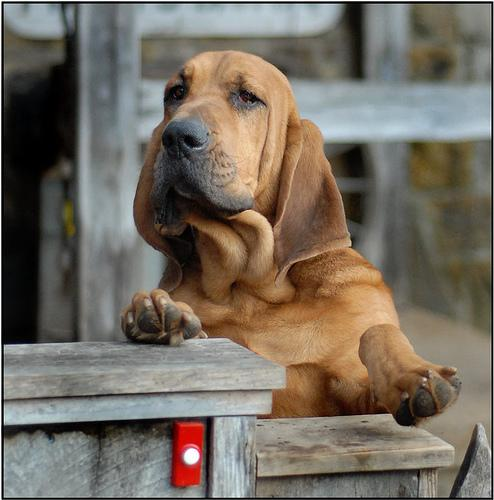

In [21]:
from tensorflow.keras.preprocessing import image
import numpy as np

# Load and preprocess the single image

# Afgan Hound
# img_path = '/kaggle/input/120-dog-breeds-breed-classification/Images/n02088094-Afghan_hound/n02088094_10832.jpg'

# Bloodhound
img_path ='/kaggle/input/120-dog-breeds-breed-classification/Images/n02088466-bloodhound/n02088466_10506.jpg'

# Beagle
# img_path = '/kaggle/input/120-dog-breeds-breed-classification/Images/n02088364-beagle/n02088364_10108.jpg'  # Replace with the path to your image
img = image.load_img(img_path, target_size=(IMAGE_HEIGHT, IMAGE_WIDTH))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
img_array /= 255.  # Normalize pixel values

# Make predictions
predictions = model.predict(img_array)

# Get predicted class labels
predicted_class = np.argmax(predictions, axis=1)

# Print the predicted class
print("Predicted Class:", predicted_class)

predicted_breeds = breed_names[predicted_class]  # Map indices to breed names
print('Predicted', predicted_breeds[0])

from IPython.display import Image

display(Image(filename=img_path))

## Testing the Data

    "My personal research and development philosophy (and hence the exercises in the book) have a strong emphasis on testing algorithms. It’s too easy in computer vision to develop analgorithm that does something plausible on a few images rather than something correct. The best way to validate your algorithms is to use a three-part strategy. First, test your algorithm on clean synthetic data, for which the exact results are known. Second, add noise to the data and evaluate how the performance degrades as a function of noise level. Finally, test the algorithm on real-world data, preferably drawn from a wide variety of sources, such as photos found on the web. Only then can you truly know if your algorithm can deal with real-world complexity, i.e., images that do not fit some simplified model or assumptions."

– Richard Szeliski

SZELISKI, RICHARD. Computer Vision: Algorithms and Applications. SPRINGER NATURE, 2023. 

First, test your algorithm on clean synthetic data

Second, add noise to the data and evaluate how the performance degrades as a function of noise level

Finally, test the algorithm on real-world data, preferably drawn from a wide variety of sources, such as photos found on the web. Only then can you truly know if your algorithm can deal with real-world complexity, i.e., images that do not fit some simplified model or assumptions."

Creating a model from scratch (Test)

First, we define a sequential model using Model with an input layer specifying the image size as 224x224. We stack convolutional layers (Conv2D) with ReLU activation for non-linearity. Max pooling layers (MaxPooling2D) are used for dimensionality reduction. The data is flattened before feeding it to fully-connected layers (Dense) with ReLU activation. The final layer has (70) units, one for each dog breed, and a softmax activation for multi-class classification.

Compilation: We compile the model with categorical crossentropy loss (suitable for multi-class classification), Adam optimizer, and accuracy metric.

Training: This part is a placeholder. You'll need to replace train_images and train_labels with your actual training data (images and one-hot encoded labels). Adjust epochs and batch size as needed. Validation data (val_images, val_labels) is used for monitoring performance and preventing overfitting.

Evaluation: We evaluate the model on the unseen test data (test_images, test_labels) and print the test accuracy.

In [22]:
from tensorflow.keras import layers
from tensorflow.keras import Model

# Define the model architecture
model = Model(inputs=layers.Input(shape=(224, 224, 3)), 
              outputs=[
                  layers.Conv2D(32, (3, 3), activation='relu')(model.input),
                  layers.MaxPooling2D((2, 2))(model.output),
                  layers.Conv2D(64, (3, 3), activation='relu')(model.output),
                  layers.MaxPooling2D((2, 2))(model.output),
                  layers.Flatten()(model.output),
                  layers.Dense(128, activation='relu')(model.output),  
                  layers.Dense(num_breeds, activation='softmax')(model.output)
              ])

ValueError: Input 0 of layer "max_pooling2d" is incompatible with the layer: expected ndim=4, found ndim=2. Full shape received: (None, 70)

In [ ]:
# Compile the model
# model.compile(loss='categorical_crossentropy',
#               optimizer='adam',
#               metrics=['accuracy'])

model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

In [ ]:
# Train the model (replace placeholders with your data)
# model.fit(train_images, train_labels, epochs=10, batch_size=32,
#           validation_data=(val_images, val_labels))

model.fit(train_generator,
          epochs=epochs,
          steps_per_epoch=len(train_generator),  # Assuming you know the number of steps
          validation_data=val_generator,
          validation_steps=len(val_generator))  # Assuming you know the number of steps

In [ ]:
# Evaluate the model on test data
# test_loss, test_acc = model.evaluate(test_images, test_labels)
# print('Test accuracy:', test_acc)

test_loss, test_acc = model.evaluate(val_generator)
print('Validation accuracy:', test_acc)
